# Case 2: the Gandak River flood seen by NISAR radar (Bihar, India, September 2026)

NISAR is the new NASA and ISRO radar satellite. A radar sends its own microwave pulses and records the echo, so it sees the ground **through clouds and at night**. That matters here: the monsoon clouds hid the September 2026 Gandak flood from optical satellites, but NISAR imaged it on the day of the peak.

This notebook, read from top to bottom:

1. **Study area**: where we look, on a satellite photo.
2. **Data**: which NISAR files, and how we fetch them with NASA's API.
3. **The raw radar**: before and after the flood, and how we clean the speckle.

Only one radar channel is used (**HH**, explained in section 2) and every rule is a simple comparison of two numbers per pixel.

In [1]:
import json
import time
import urllib.request
from pathlib import Path

import earthaccess
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray  # noqa: F401  (adds the .rio tools to xarray)
import xarray as xr
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from pyproj import Transformer
from scipy import ndimage

DATA = Path("../data/case2")      # this notebook lives in dataScience/notebooks/
CACHE = DATA / "cache"            # downloads (large, not committed to git)
EXPORT = DATA / "export"          # the package for the app (small, committed)
CACHE.mkdir(parents=True, exist_ok=True)
EXPORT.mkdir(parents=True, exist_ok=True)

BBOX = (84.15, 26.10, 84.75, 26.60)   # study box: west, south, east, north (degrees)
UTM = 32644                           # UTM zone 44N: the map grid of the NISAR files here
PIXEL_M = 20                          # analysis pixel size (metres)
BEFORE, PEAK, AFTER = "2026-09-04", "2026-09-28", "2026-10-10"

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "font.size": 9})

### Map helpers

All maps share one grid: 20 m pixels in UTM zone 44N covering the study box. Every radar date and the satellite photo are resampled onto it, so pixel `[row, col]` is the same spot on the ground in every image.

In [2]:
def make_grid(bbox, epsg, res):
    """Empty 20 m grid (UTM) that covers the lon/lat box."""
    tr = Transformer.from_crs(4326, epsg, always_xy=True)
    xs, ys = tr.transform([bbox[0], bbox[2], bbox[0], bbox[2]], [bbox[1], bbox[1], bbox[3], bbox[3]])
    x0, x1 = np.floor(min(xs) / res) * res, np.ceil(max(xs) / res) * res
    y0, y1 = np.floor(min(ys) / res) * res, np.ceil(max(ys) / res) * res
    x = np.arange(x0 + res / 2, x1, res)
    y = np.arange(y1 - res / 2, y0, -res)
    return xr.DataArray(np.zeros((y.size, x.size), "float32"), coords={"y": y, "x": x}, dims=("y", "x")).rio.write_crs(epsg)


GRID = make_grid(BBOX, UTM, PIXEL_M)
EXTENT = [float(GRID.x[0]) - 10, float(GRID.x[-1]) + 10, float(GRID.y[-1]) - 10, float(GRID.y[0]) + 10]
to_utm = Transformer.from_crs(4326, UTM, always_xy=True).transform


def box_utm(w, s, e, n):
    """Outline of a lon/lat box in grid coordinates (for drawing)."""
    lon = [w, e, e, w, w]
    lat = [s, s, n, n, s]
    return to_utm(lon, lat)


def zoom_to(ax, w, s, e, n):
    xs, ys = box_utm(w, s, e, n)
    ax.set_xlim(min(xs), max(xs))
    ax.set_ylim(min(ys), max(ys))


def scale_bar(ax, km=10):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x, y = x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0)
    ax.plot([x, x + km * 1000], [y, y], color="white", lw=3)
    ax.text(x + km * 500, y + 0.015 * (y1 - y0), f"{km} km", color="white", ha="center", fontsize=8)


def radar_axes(ax, title):
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def show_radar(ax, db, title, vmin=-25, vmax=0):
    """Grey radar image in dB: dark = little echo (smooth water), bright = strong echo."""
    im = ax.imshow(db, cmap="gray", vmin=vmin, vmax=vmax, extent=EXTENT, interpolation="nearest")
    radar_axes(ax, title)
    return im


def show_classes(ax, codes, colors):
    """Colour the pixels whose code is in `colors` ({code: hex}); others stay transparent."""
    rgba = np.zeros(codes.shape + (4,), "uint8")   # 8-bit colours keep the memory low
    for k, hexcol in colors.items():
        rgba[codes == k] = [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)] + [255]
    ax.imshow(rgba, extent=EXTENT, interpolation="nearest")


print(f"Grid: {GRID.sizes['y']} x {GRID.sizes['x']} pixels of {PIXEL_M} m, EPSG:{UTM}")

Grid: 2853 x 3071 pixels of 20 m, EPSG:32644


## 1. The study area, seen from space

The **Gandak River** comes down from the Himalaya in Nepal and crosses the plain of Bihar (India) towards the Ganges. Our box is about **60 km by 55 km** around **Gopalganj**, on the Gandak floodplain.

What happened: heavy rain in Nepal on **September 26 and 27, 2026** pushed the Gandak to a record **91.25 m at Bagaha**. The Valmikinagar barrage released **543,500 cusecs** on the morning of **September 28**, and embankments breached in West Champaran and at **Sheetalpur (Gopalganj)**. NISAR passed over the box that same evening.

The photo below is a normal colour image from the European **Sentinel-2** satellite on **June 25, 2026**, before the monsoon flood and with no cloud. It shows the river, the fields and the towns we refer to later. It is fetched from the free **Earth Search** catalogue (no login).

In [3]:
STAC = "https://earth-search.aws.element84.com/v1/search"


def stac_search(collection, bbox, day):
    """Images of one collection that touch the box on one day (public STAC API)."""
    body = {"collections": [collection], "bbox": list(bbox), "limit": 20,
            "datetime": f"{day}T00:00:00Z/{day}T23:59:59Z"}
    req = urllib.request.Request(STAC, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"})
    return json.load(urllib.request.urlopen(req, timeout=120))["features"]


def sentinel2_photo(day):
    """True-colour Sentinel-2 photo on our grid; tiles are read over the internet, only the box is kept."""
    path = CACHE / f"sentinel2_{day}.tif"
    if path.exists():
        return rioxarray.open_rasterio(path)
    items = sorted(stac_search("sentinel-2-l2a", BBOX, day), key=lambda f: f["properties"]["eo:cloud_cover"])
    rgb = None
    for item in items:
        tile = rioxarray.open_rasterio(item["assets"]["visual"]["href"], overview_level=0)  # 20 m version
        try:
            tile = tile.rio.clip_box(*BBOX, crs="EPSG:4326")
        except Exception:
            continue  # this tile does not touch the box
        part = tile.rio.reproject_match(GRID, nodata=0)
        rgb = part if rgb is None else rgb.where((rgb != 0).any("band"), part)
        print(f"  {item['id']}: {item['properties']['eo:cloud_cover']:.1f} % cloud")
    rgb = rgb.astype("uint8").rio.write_crs(UTM)
    rgb.rio.to_raster(path, compress="deflate")
    return rgb


PHOTO_DAY = "2026-06-25"
photo = sentinel2_photo(PHOTO_DAY)
photo_rgb = np.moveaxis(photo.values, 0, -1)

In [4]:
import osmnx as ox

OVERPASS = ("https://overpass-api.de/api", "https://overpass.kumi.systems/api")
ox.settings.cache_folder = str(CACHE / "osmnx")   # osmnx's own download cache, kept with ours (not committed)


def osm(tags, name):
    """OpenStreetMap features in the box (Overpass API), cached as GeoJSON."""
    path = CACHE / f"osm_{name}.geojson"
    if path.exists():
        return gpd.read_file(path)
    for attempt in range(3):
        for url in OVERPASS:
            try:
                ox.settings.overpass_url = url
                gdf = ox.features_from_bbox(BBOX, tags).reset_index()
                cols = [c for c in ("name", "place", "waterway") if c in gdf.columns]
                gdf = gdf[cols + ["geometry"]]
                gdf.to_file(path, driver="GeoJSON")
                return gdf
            except Exception as exc:
                print(f"  Overpass {url} failed ({type(exc).__name__}), trying again")
        time.sleep(20 * (attempt + 1))
    raise RuntimeError("OpenStreetMap is not reachable right now; run this cell again later")


towns = osm({"place": ["city", "town"]}, "towns")
towns = towns[(towns.geometry.geom_type == "Point") & towns["name"].notna()].reset_index(drop=True)
rivers = osm({"waterway": "river"}, "rivers")
gandak = rivers[(rivers["name"] == "Gandak") & rivers.geometry.geom_type.isin(["LineString", "MultiLineString"])]
print("Towns:", ", ".join(towns["name"]))
print("Gandak river segments:", len(gandak))

# World map for the small locator inset (Natural Earth, public domain)
world_path = CACHE / "natural_earth_countries.geojson"
if not world_path.exists():
    gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip").to_file(world_path, driver="GeoJSON")
world = gpd.read_file(world_path)

Towns: Siwan, Mirganj, Mairwa, Gopalganj, Barharia, Maharajganj
Gandak river segments: 8


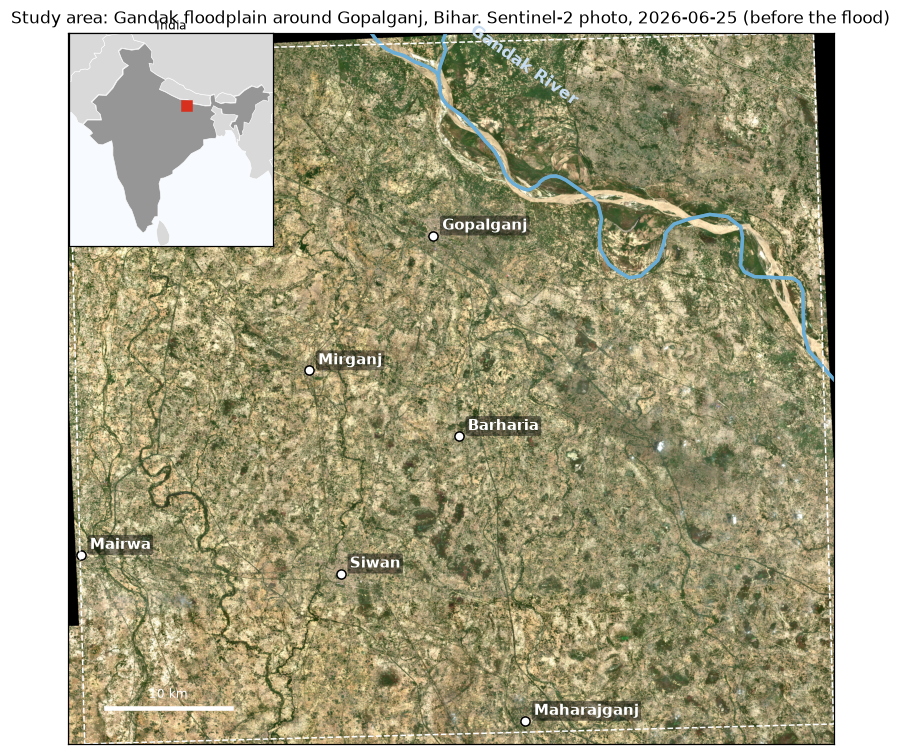

In [5]:
fig, ax = plt.subplots(figsize=(9, 8.4))
ax.imshow(photo_rgb, extent=EXTENT)
for geom in gandak.to_crs(UTM).geometry:
    for line in getattr(geom, "geoms", [geom]):
        ax.plot(*line.xy, color="#6baed6", lw=2.2, alpha=0.9)
for _, t in towns.to_crs(UTM).iterrows():
    ax.plot(t.geometry.x, t.geometry.y, "o", ms=6, mfc="white", mec="black")
    ax.annotate(t["name"], (t.geometry.x, t.geometry.y), xytext=(6, 4), textcoords="offset points",
                color="white", fontsize=10, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="black", alpha=0.45, lw=0))
gx, gy = to_utm(84.47, 26.555)
ax.annotate("Gandak River", (gx, gy), color="#c6dbef", fontsize=11, fontweight="bold", rotation=-35)
ax.plot(*box_utm(*BBOX), color="white", lw=1, ls="--")
ax.set_xlim(EXTENT[:2])
ax.set_ylim(EXTENT[2:])
radar_axes(ax, f"Study area: Gandak floodplain around Gopalganj, Bihar. Sentinel-2 photo, {PHOTO_DAY} (before the flood)")
scale_bar(ax)

inset = ax.inset_axes([0.0, 0.70, 0.27, 0.30])
world.plot(ax=inset, color="#d9d9d9", edgecolor="white", lw=0.4)
world[world["NAME"] == "India"].plot(ax=inset, color="#969696", edgecolor="white", lw=0.4)
inset.plot(np.mean(BBOX[::2]), np.mean(BBOX[1::2]), "s", color="#d7301f", ms=6)
inset.set_xlim(66, 98)
inset.set_ylim(6, 37)
inset.set_xticks([])
inset.set_yticks([])
inset.set_xlabel("")
inset.set_ylabel("")
inset.set_facecolor("#f7fbff")
inset.set_title("India", fontsize=8, pad=2)
plt.show()

## 2. The NISAR data and how we fetch it

| | |
|---|---|
| Satellite | NISAR (NASA and ISRO), launched July 2025 |
| Radar | **L-band**, 24 cm wavelength: passes through clouds and rain |
| Product | **GCOV level 2** (calibrated backscatter on a map grid), collection `NISAR_L2_GCOV_PROVISIONAL_V1` |
| Pixel | 20 m (some passes are delivered at 10 m; we average them to 20 m) |
| Pass used | **track 149, descending, frame 75**: same orbit, same viewing angle, every 12 days at 13:07 UTC |
| Channel used | **HH** (sent horizontal, received horizontal) |
| Archive | NASA Earthdata (Alaska Satellite Facility), free account, password in `~/.netrc` |

"Provisional" means calibrated data released before the official validation (validated products start on October 21, 2026); it is the only NISAR data covering this flood.

**Why HH only.** The radar sends a horizontal wave (H) and listens in two ways: horizontal (HH) and vertical (HV).
- **HH** reacts to water and to the "corner" between water and walls or stems: it is the flood channel.
- **HV** mostly measures the volume of leaves and branches; it is useful to follow crops over a season. Over the 24 days between our two flood dates the plants change little, so HV adds nothing to the flood map. We read HV once per date only to detect a known acquisition defect (below).

**How the API works.** Each NISAR file covers about 240 km by 240 km and weighs 4 to 7 GB. We do not download it: `earthaccess` finds the files in NASA's catalogue (CMR), then we open each file over HTTPS and read **only the pixels of our box** (about 40 to 160 MB per date). The result is saved in `data/case2/cache/`, so the next run takes seconds.

In [6]:
results = earthaccess.search_data(short_name="NISAR_L2_GCOV_PROVISIONAL_V1", bounding_box=BBOX,
                                  temporal=("2026-06-01", "2026-10-20"))

rows = []
for g in results:
    name = g["umm"]["GranuleUR"]
    p = name.split("_")  # NISAR_L2_PR_GCOV_<cycle>_<track>_<A|D>_<frame>_<mode>_<pols>_<..>_<start>_<end>_<..>_N_<F|P>_..
    url = [u for u in g.data_links(access="external") if u.endswith(".h5")][0]
    rows.append({"date": f"{p[11][:4]}-{p[11][4:6]}-{p[11][6:8]}", "track": p[5] + p[6], "frame": p[7],
                 "mode": p[8], "channels": p[9], "full_frame": p[-3] == "F", "file": name, "url": url})
files = pd.DataFrame(rows).sort_values("date")
print(f"{len(files)} NISAR files touch the box between June and October 2026, per pass:")
print(files.groupby(["track", "frame"]).date.nunique().rename("dates").to_string())

57 NISAR files touch the box between June and October 2026, per pass:
track  frame
026A   015       8
048D   075       9
       076       9
098A   015      10
149D   075       9


Several passes cover the box. We keep **track 149D frame 075** because it is the only one that covers the whole box on all the key dates, including the flood peak. For each date we take the file with the two channels HH and HV (`DHDH`) that covers the full frame.

In [7]:
use = files[(files.track == "149D") & (files.frame == "075") & (files.channels == "DHDH") & files.full_frame]
use = use.drop_duplicates("date").reset_index(drop=True)
DATES = list(use.date)
use[["date", "mode", "channels", "file"]]

,date,mode,channels,file
0,2026-06-24,4005,DHDH,NISAR_L2_PR_GCOV_023_149_D_075_4005_DHDH_A_202...
1,2026-07-06,2005,DHDH,NISAR_L2_PR_GCOV_024_149_D_075_2005_DHDH_M_202...
2,2026-07-18,4005,DHDH,NISAR_L2_PR_GCOV_025_149_D_075_4005_DHDH_A_202...
3,2026-08-11,4005,DHDH,NISAR_L2_PR_GCOV_027_149_D_075_4005_DHDH_A_202...
4,2026-09-04,2005,DHDH,NISAR_L2_PR_GCOV_029_149_D_075_2005_DHDH_M_202...
5,2026-09-28,2005,DHDH,NISAR_L2_PR_GCOV_031_149_D_075_2005_DHDH_M_202...
6,2026-10-10,2005,DHDH,NISAR_L2_PR_GCOV_032_149_D_075_2005_DHDH_M_202...


### Reading and cleaning one date

For each date: open the file over HTTPS, keep the box, average 10 m products to 20 m, put it on our grid and convert the echo to **decibels**:

$$\text{dB} = 10 \cdot \log_{10}(\text{echo power})$$

So 0 dB is a strong echo, -10 dB is 10 times weaker, -20 dB is 100 times weaker. Calm water sits around -18 to -20 dB; fields around -10 dB; towns above -5 dB.

**One defect.** On some passes (here September 4 and 28) a straight band 2 to 3 km wide falls below the radar's noise floor (HV under -32 dB) from one edge of the image to the other. It is a gap in the acquisition, not water, so we blank it (no data) before any rule is applied. The test looks for a long, straight, very dark band that crosses the whole image; a river meanders, so it is not caught.

In [8]:
earthaccess.login(strategy="netrc")
GROUP = "/science/LSAR/GCOV/grids/frequencyA"   # where the 20 m HH and HV images sit in the file


def read_window(url):
    """Stream only our box from one NISAR file: HH and HV echo power, at 20 m."""
    fs = earthaccess.get_fsspec_https_session()
    with fs.open(url, "rb", cache_type="blockcache", block_size=8 * 2**20) as f:
        ds = xr.open_dataset(f, engine="h5netcdf", group=GROUP, phony_dims="sort",
                             drop_variables=["listOfCovarianceTerms", "listOfPolarizations"])
        epsg = int(ds["projection"].attrs.get("epsg_code", ds["projection"].values))
        assert epsg == UTM, f"unexpected map projection EPSG:{epsg}"
        x, y = ds["xCoordinates"].values, ds["yCoordinates"].values
        xmin, ymin, xmax, ymax = GRID.rio.bounds()
        cols = np.where((x > xmin - 40) & (x < xmax + 40))[0]
        rows = np.where((y > ymin - 40) & (y < ymax + 40))[0]
        win = ds[["HHHH", "HVHV"]].isel(xCoordinates=slice(cols[0], cols[-1] + 1),
                                         yCoordinates=slice(rows[0], rows[-1] + 1)).load()
    win = win.rename(xCoordinates="x", yCoordinates="y")
    step = abs(float(x[1] - x[0]))
    if step < PIXEL_M:  # 10 m product: average blocks of 2 x 2 pixels
        f = int(round(PIXEL_M / step))
        win = win.coarsen(x=f, y=f, boundary="trim").mean()
    return win.rio.write_crs(UTM)


def to_db(power):
    return 10 * np.log10(np.where(power > 0, power, np.nan))


def find_stripe(hv_db):
    """Straight band below the noise floor (HV < -32 dB) crossing the whole image: an acquisition gap."""
    low = ndimage.binary_closing(np.nan_to_num(hv_db, nan=0) < -32, structure=np.ones((15, 15)))
    labels, n = ndimage.label(low)
    stripe = np.zeros(low.shape, bool)
    if n == 0:
        return stripe
    sizes = ndimage.sum(low, labels, range(1, n + 1))
    for lab in np.argsort(sizes)[::-1][:3] + 1:          # the three largest dark patches
        band = labels == lab
        rows = np.where(band.any(axis=1))[0]
        if rows.size < 0.8 * band.shape[0] or np.median(band[rows].sum(axis=1)) > 400:
            continue                                        # must cross the image and stay narrow
        r = rows[::20]
        centre = np.array([np.where(band[i])[0].mean() for i in r])
        line = np.polyval(np.polyfit(r, centre, 1), r)
        if 1 - np.var(centre - line) / max(np.var(centre), 1e-9) > 0.98:   # and follow a straight line
            stripe |= ndimage.binary_dilation(band, iterations=15)
    return stripe


def load_date(row):
    """HH in dB on our grid for one date (cached), with the stripe blanked."""
    path = CACHE / f"nisar_hh_{row.date}.nc"
    if not path.exists():
        t0 = time.time()
        for attempt in range(3):   # NASA's server sometimes answers "502 Bad Gateway": wait and try again
            try:
                win = read_window(row.url).rio.reproject_match(GRID)
                break
            except Exception as exc:
                if attempt == 2:
                    raise
                print(f"  {row.date}: {type(exc).__name__}, trying again in {30 * (attempt + 1)} s")
                time.sleep(30 * (attempt + 1))
        hh, hv = to_db(win["HHHH"].values), to_db(win["HVHV"].values)
        stripe = find_stripe(hv)
        hh[stripe] = np.nan
        out = GRID.copy(data=hh.astype("float32")).rename("HH")
        out.attrs = {"file": row.file, "mode": row["mode"], "stripe_pixels": int(stripe.sum()), "units": "dB"}
        out.to_netcdf(path)
        print(f"  {row.date}: streamed in {time.time() - t0:.0f} s, stripe pixels: {int(stripe.sum()):,}")
        del win, hv
    return xr.open_dataset(path)["HH"].load().rio.write_crs(UTM)


scenes = [load_date(r) for _, r in use.iterrows()]
RAW = xr.concat(scenes, dim=pd.Index(DATES, name="date")).rio.write_crs(UTM)   # HH (dB) as delivered, one image per date
del scenes
summary = pd.DataFrame({"date": DATES,
                        "mode": [use.loc[i, "mode"] for i in range(len(DATES))],
                        "valid pixels %": [round(float(np.isfinite(RAW.sel(date=d)).mean() * 100), 1) for d in DATES],
                        "stripe blanked (km2)": [round(xr.open_dataset(CACHE / f"nisar_hh_{d}.nc")["HH"].attrs["stripe_pixels"] * PIXEL_M**2 / 1e6, 1) for d in DATES]})
summary

,date,mode,valid pixels %,stripe blanked (km2)
0,2026-06-24,4005,94.1,0.0
1,2026-07-06,2005,94.1,0.0
2,2026-07-18,4005,94.1,0.0
3,2026-08-11,4005,94.0,0.0
4,2026-09-04,2005,85.6,202.7
5,2026-09-28,2005,85.4,205.3
6,2026-10-10,2005,94.0,0.0


## 3. The raw radar: before and after

Same grey scale on both dates (-25 dB black, 0 dB white). Look for the river: it is **black** (calm water sends the pulse away like a mirror). On September 28 large new black areas appear next to the river.

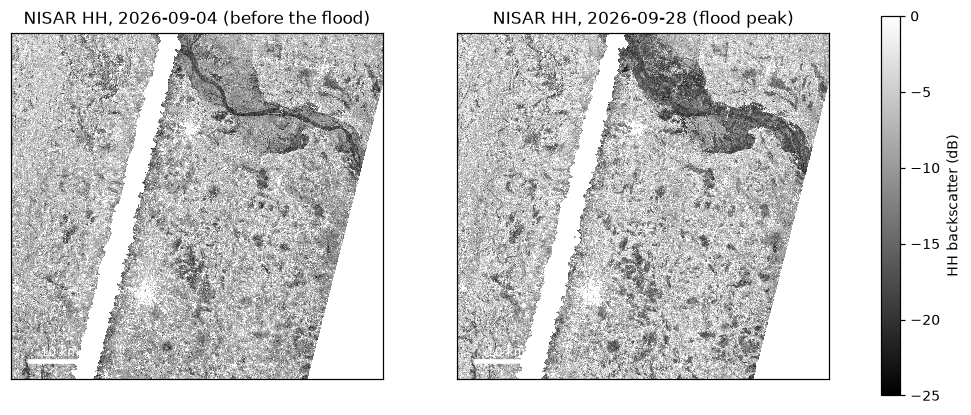

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, d, label in zip(axes, (BEFORE, PEAK), ("before the flood", "flood peak")):
    im = show_radar(ax, RAW.sel(date=d), f"NISAR HH, {d} ({label})")
    scale_bar(ax)
fig.colorbar(im, ax=axes, shrink=0.8, label="HH backscatter (dB)")
plt.show()

### Speckle, and how we clean it

A radar image is grainy: each pixel adds echoes from many small objects, which randomly reinforce or cancel each other (**speckle**). A single pixel can jump by several dB with no change on the ground. We replace each pixel by the **median of the 5 x 5 pixels** around it (100 m by 100 m). Edges of rivers and fields stay sharp, isolated jumps disappear. All the rules below use this cleaned image; the raw one is also exported so both can be compared in the app.

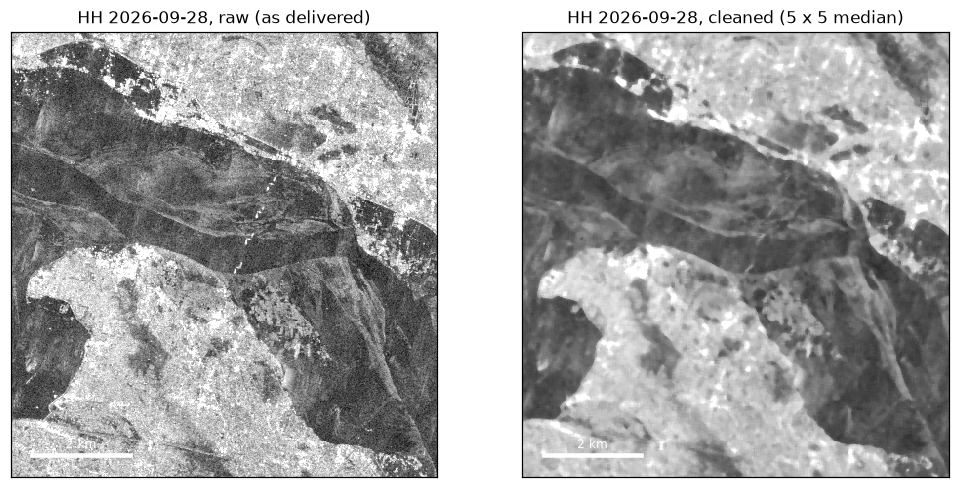

In [10]:
def despeckle(db, size=5):
    """5 x 5 median filter that keeps the no-data gaps."""
    a = db.values
    ok = np.isfinite(a)
    out = ndimage.median_filter(np.where(ok, a, np.nanmedian(a)), size=size)
    out[~ok] = np.nan
    return db.copy(data=out.astype("float32"))


CLEAN = xr.concat([despeckle(RAW.sel(date=d)) for d in DATES], dim=pd.Index(DATES, name="date")).rio.write_crs(UTM)

ZOOM = (84.625, 26.42, 84.71, 26.50)   # 8.5 km x 9 km east of Gopalganj, used for every close-up
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
for ax, img, label in zip(axes, (RAW, CLEAN), ("raw (as delivered)", "cleaned (5 x 5 median)")):
    show_radar(ax, img.sel(date=PEAK), f"HH {PEAK}, {label}")
    zoom_to(ax, *ZOOM)
    scale_bar(ax, km=2)
plt.show()

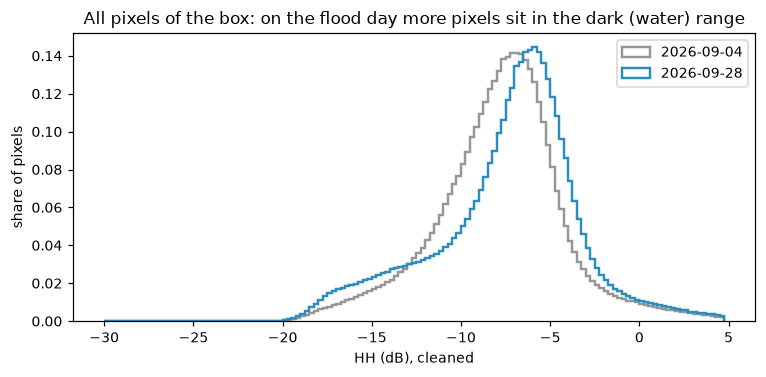

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(-30, 5, 0.25)
for d, color in ((BEFORE, "#969696"), (PEAK, "#2b8cbe")):
    v = CLEAN.sel(date=d).values
    ax.hist(v[np.isfinite(v)], bins=bins, histtype="step", lw=1.6, color=color, density=True, label=d)
ax.set_xlabel("HH (dB), cleaned")
ax.set_ylabel("share of pixels")
ax.set_title("All pixels of the box: on the flood day more pixels sit in the dark (water) range")
ax.legend()
plt.show()

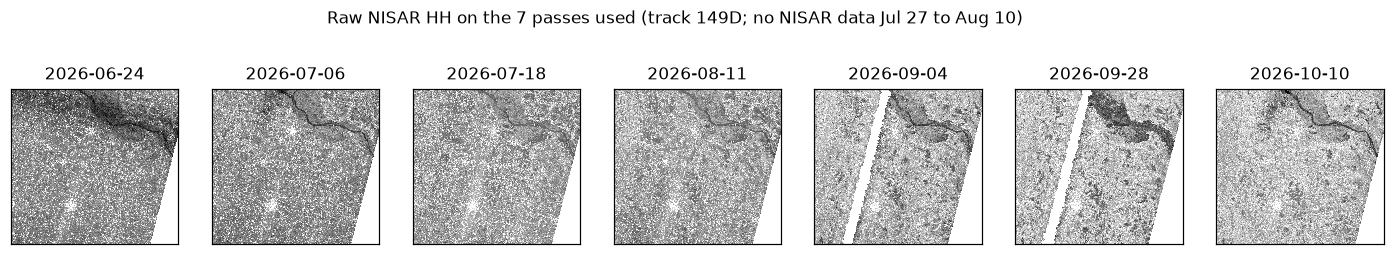

In [12]:
fig, axes = plt.subplots(1, len(DATES), figsize=(2.3 * len(DATES), 2.6))
for ax, d in zip(axes, DATES):
    show_radar(ax, RAW.sel(date=d).values[::3, ::3], d)
fig.suptitle("Raw NISAR HH on the 7 passes used (track 149D; no NISAR data Jul 27 to Aug 10)", y=1.04)
plt.show()